### This Agentic AI system provides a data-driven, automated approach to optimize brownfield development by:
Identifying sweet spots using deep learning
Maximizing production with reinforcement learning
Recommending optimal well locations with genetic algorithms

### pip install gymnasium stable-baselines3 tensorflow geneticalgorithm pandas numpy matplotlib scikit-learn

#### Keith R. Holdaway

### To implement the Agentic AI for Reservoir Optimization, we need three key datasets:

Well Logs (well_logs.csv) – Petrophysical properties

Production Data (production_data.csv) – Historical well performance

Seismic Attributes (seismic_attributes.csv) – Spatial reservoir properties



### Well Logs

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)
well_ids = ['Well_A', 'Well_B', 'Well_C']
depths = np.arange(3000, 3200, 0.5)
data = {
    'WELL_ID': np.random.choice(well_ids, len(depths)),
    'DEPTH': depths,
    'GR': np.clip(40 + 70 * np.exp(-0.002*(depths - 3100)**2) + 10 * np.sin(0.1*depths) + 5 * np.random.randn(len(depths)), 40, 120),
    'RHOB': np.clip(2.65 - 0.3 * np.exp(-0.001*(depths - 3150)**2) + 0.1 * np.cos(0.05*depths) + 0.05 * np.random.randn(len(depths)), 1.9, 2.9),
    'RT': np.clip(10 * np.exp(-0.0005*(depths - 3120)**2) + 0.5 * np.sin(0.07*depths) + 0.1 * np.random.randn(len(depths)), 0.2, 100),
    'PHIE': np.clip(0.25 * np.exp(-0.0005*(depths - 3100)**2) + 0.05 * np.random.randn(len(depths)), 0.05, 0.35),
    'VSH': np.clip(0.4 * np.exp(-0.0003*(depths - 3080)**2) + 0.1 * np.random.randn(len(depths)), 0, 1),
    'SW': np.clip(0.6 * np.exp(-0.0004*(depths - 3140)**2) + 0.1 * np.random.randn(len(depths)), 0.1, 0.9),
    'PERM': np.clip(100 * np.exp(-0.0006*(depths - 3120)**2) + 20 * np.random.randn(len(depths)), 10, 500)
}

well_logs = pd.DataFrame(data)
well_logs.to_csv('well_logs_AgenticAI.csv', index=False)

### Production Data

In [ ]:
dates = pd.date_range(start='2020-01-01', end='2023-12-01', freq='ME')
wells = ['Well_A', 'Well_B', 'Well_C']
prod_data = []
for well in wells:
    for date in dates:
        oil = np.clip(400 + 100 * np.sin(0.1 * len(prod_data)) + 30 * np.random.randn(), 100, 800)
        water = np.clip(100 + 40 * np.sin(0.2 * len(prod_data)) + 20 * np.random.randn(), 20, 300)
        gas = np.clip(150 + 50 * np.sin(0.15 * len(prod_data)) + 25 * np.random.randn(), 50, 400)
        cum_oil = len(prod_data) * oil / 1000 + np.random.uniform(50, 200)
        cum_water = len(prod_data) * water / 1000 + np.random.uniform(10, 50)
        prod_data.append([well, date.strftime('%Y-%m-%d'), oil, water, gas, cum_oil, cum_water])

production_data = pd.DataFrame(prod_data, columns=[
    'WELL_ID', 'DATE', 'OIL_RATE', 'WATER_RATE', 'GAS_RATE', 'CUM_OIL', 'CUM_WATER'
])
production_data.to_csv('production_data.csv', index=False)

In [ ]:
from datetime import datetime, timedelta

def generate_production_data(num_wells=5, days=365):
    """Generate synthetic production data for multiple wells"""
    np.random.seed(42)
    
    # Create date range
    start_date = datetime(2020, 1, 1)
    dates = [start_date + timedelta(days=i) for i in range(days)]
    
    # Generate data for each well
    data = []
    for well_num in range(1, num_wells + 1):
        well_id = f"Well_{well_num}"
        
        # Base decline curve
        base_rate = 1000 * np.exp(-0.001 * np.arange(days))
        
        # Add well-specific variations
        variation = np.random.normal(0, 50, days)
        oil_rate = np.clip(base_rate + variation, 50, 1200)
        
        # Water cut increases over time
        water_cut = 0.2 + 0.6 * (1 - np.exp(-0.005 * np.arange(days)))
        
        # Choke size varies around a mean
        choke_size = np.random.normal(50, 10, days)
        choke_size = np.clip(choke_size, 20, 80)
        
        # Bottom hole pressure declines
        bhp = 3000 - 5 * np.arange(days) + np.random.normal(0, 50, days)
        bhp = np.clip(bhp, 500, 3500)
        
        # Create well data
        for day in range(days):
            data.append({
                'DATE': dates[day],
                'WELL_ID': well_id,
                'OIL_RATE': oil_rate[day],
                'GAS_RATE': oil_rate[day] * np.random.uniform(0.8, 1.2),
                'WATER_CUT': water_cut[day],
                'CHOKE_SIZE': choke_size[day],
                'BHP': bhp[day],
                'STATUS': 'ON' if np.random.random() > 0.02 else 'DOWN'  # 2% downtime
            })
    
    return pd.DataFrame(data)

# Generate and save production data
production_df = generate_production_data()
production_df.to_csv('production_data.csv', index=False)

print("production_data.csv generated successfully with columns:")
print(production_df.columns.tolist())
print("\nSample data:")
print(production_df.head())

### Seismic Attributes

In [ ]:
x_coords = np.arange(100, 200, 5)
y_coords = np.arange(200, 300, 5)
seismic_data = []
for x in x_coords:
    for y in y_coords:
        amplitude = np.clip(0.8 + 0.2 * np.sin(0.05*x) * np.cos(0.05*y) + 0.1 * np.random.randn(), 0.5, 1.0)
        coherence = np.clip(0.9 + 0.1 * np.cos(0.03*x) * np.sin(0.03*y) + 0.05 * np.random.randn(), 0.7, 1.0)
        impedance = 6000 + 1000 * np.exp(-0.0001*((x-150)**2 + (y-250)**2)) + 300 * np.random.randn()
        porosity = np.clip(0.2 + 0.1 * np.exp(-0.0002*((x-140)**2 + (y-260)**2)) + 0.03 * np.random.randn(), 0.05, 0.35)
        perm = np.clip(100 + 50 * np.exp(-0.0002*((x-145)**2 + (y-255)**2)) + 20 * np.random.randn(), 10, 300)
        oil_sat = np.clip(0.7 + 0.2 * np.exp(-0.0003*((x-155)**2 + (y-245)**2)) + 0.1 * np.random.randn(), 0.1, 0.9)
        seismic_data.append([x, y, amplitude, coherence, impedance, porosity, perm, oil_sat])

seismic_attrs = pd.DataFrame(seismic_data, columns=[
    'X_COORD', 'Y_COORD', 'AMPLITUDE', 'COHERENCE', 'IMPEDANCE', 'POROSITY', 'PERMEABILITY', 'OIL_SAT'
])
seismic_attrs.to_csv('seismic_attributes.csv', index=False)

### Petrophysical Parameters

In [1]:
import numpy as np
import pandas as pd

def generate_petrophysical_data(num_samples=2000):
    """Generate synthetic petrophysical data with realistic distributions"""
    np.random.seed(42)
    
    # Create depth array from 3000m to 4000m
    depth = np.linspace(3000, 4000, num_samples)
    
    # Generate base properties with depth trends
    porosity_base = 0.15 + 0.15 * np.exp(-0.0001*(depth-3500)**2)
    perm_base = 50 + 450 * (porosity_base/0.3)**2.5
    sw_base = 0.2 + 0.6 * (1 - np.exp(-0.0001*(depth-3500)**2))
    
    # Add random variations
    porosity = np.clip(porosity_base + np.random.normal(0, 0.02, num_samples), 0.05, 0.35)
    permeability = np.clip(perm_base * np.random.lognormal(0, 0.3, num_samples), 1, 2000)
    water_saturation = np.clip(sw_base + np.random.normal(0, 0.05, num_samples), 0.1, 0.9)
    net_to_gross = np.clip(0.7 + 0.3 * np.sin(0.002*depth) + np.random.normal(0, 0.1, num_samples), 0.3, 1.0)
    brittleness = np.clip(0.4 + 0.4*(porosity-0.05)/0.3 + np.random.normal(0, 0.1, num_samples), 0.2, 0.9)
    vsh = np.clip(0.3 + 0.5 * np.exp(-0.0002*(depth-3400)**2) + np.random.normal(0, 0.1, num_samples), 0, 1)
    
    # Create the DataFrame
    data = {
        'DEPTH': depth,
        'POROSITY': porosity,
        'PERMEABILITY': permeability,
        'SW': water_saturation,
        'NTG': net_to_gross,
        'BRITTLE': brittleness,
        'VSH': vsh,
        'PAY_FLAG': ((net_to_gross * (1 - water_saturation)) > 0.2).astype(int)
    }
    
    df = pd.DataFrame(data)
    
    # Add lithology classes
    conditions = [
        (df['VSH'] > 0.5) & (df['POROSITY'] < 0.15),  # Shale
        (df['VSH'] < 0.3) & (df['POROSITY'] > 0.2),   # Sandstone
        (df['POROSITY'] > 0.25) & (df['BRITTLE'] > 0.6)  # Carbonate
    ]
    choices = [1, 2, 3]
    df['LITHOLOGY'] = np.select(conditions, choices, default=0)
    
    return df

# Generate and save the data
petro_data = generate_petrophysical_data()
petro_data.to_csv('petrophysical_params.csv', index=False)

print("Successfully generated petrophysical_params.csv with columns:")
print(petro_data.columns.tolist())
print("\nFirst 5 rows:")
print(petro_data.head())

Successfully generated petrophysical_params.csv with columns:
['DEPTH', 'POROSITY', 'PERMEABILITY', 'SW', 'NTG', 'BRITTLE', 'VSH', 'PAY_FLAG', 'LITHOLOGY']

First 5 rows:
         DEPTH  POROSITY  PERMEABILITY        SW       NTG   BRITTLE  \
0  3000.000000  0.159934    105.795678  0.756825  0.504767  0.543277   
1  3000.500250  0.147235    124.052833  0.798440  0.553371  0.479281   
2  3001.000500  0.162954    102.139259  0.800901  0.522546  0.533368   
3  3001.500750  0.180461    118.116885  0.823632  0.562241  0.645421   
4  3002.001001  0.145317     73.404023  0.731657  0.595914  0.654875   

        VSH  PAY_FLAG  LITHOLOGY  
0  0.232151         0          0  
1  0.269450         0          0  
2  0.240262         0          0  
3  0.311042         0          0  
4  0.419718         0          0  


### Agentic AI Workflows

===== Brownfield Reservoir Optimization System =====
Initializing...

Loading and validating data...

=== Reservoir Characterization ===
Reservoir model trained with final MSE: 58701.30

=== Production Optimization ===
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 3.86e+06 |
| time/              |          |
|    fps             | 1134     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 100           |
|    ep_rew_mean          | 3.82e+06      |
| time/                   |               |
|    fps                  | 553           |
|    iterations           | 2             |
|    time_elapsed         | 7          

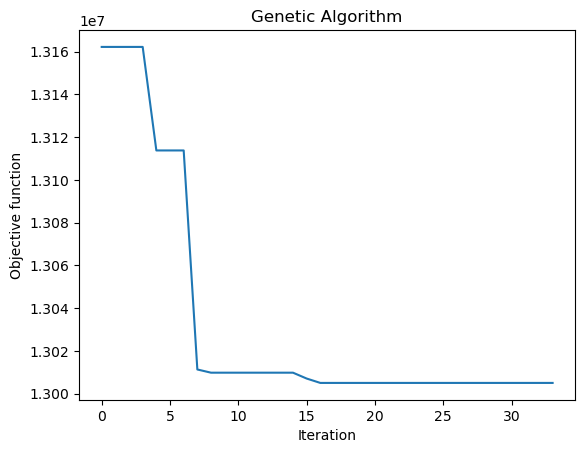


Optimal well location found at grid cell (76, 53)
Properties at location: Porosity=0.350, Permeability=772.6mD, Oil Saturation=0.757

Generating visualization...


<Figure size 1500x500 with 0 Axes>

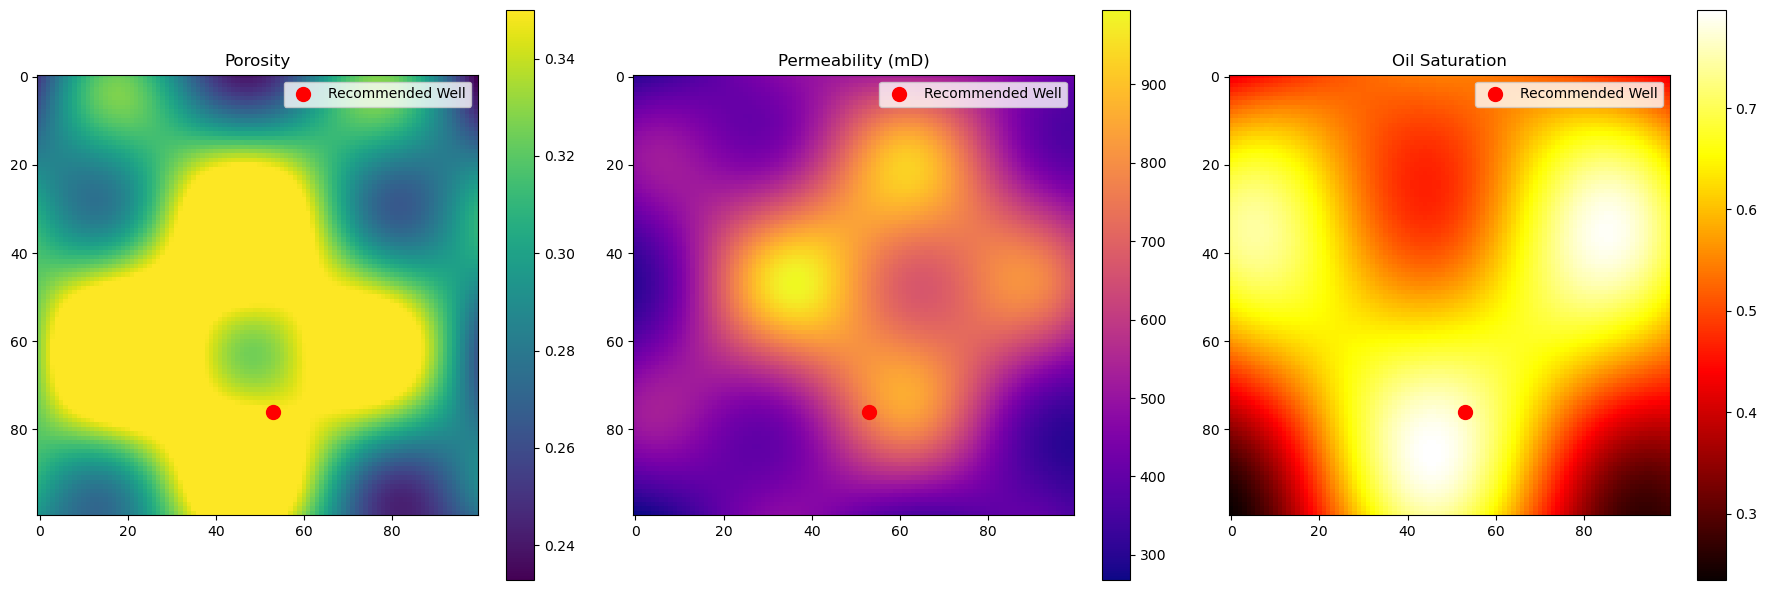


===== Optimization Complete =====
Recommended new well location: Grid (X=76, Y=53)


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Input
from geneticalgorithm import geneticalgorithm as ga
import gymnasium as gym
from stable_baselines3 import PPO
from stable_baselines3.common.env_checker import check_env

# ======================
# 1. DATA LOADING & PREPROCESSING
# ======================
class ReservoirDataLoader:
    def __init__(self, well_logs_path, production_data_path, seismic_path):
        self.well_logs = self._load_and_validate(well_logs_path, 'well logs', 
                                               ['WELL_ID', 'DEPTH', 'GR', 'RHOB', 'RT', 'PHIE', 'VSH', 'SW', 'PERM'])
        self.production_data = self._load_and_validate(production_data_path, 'production data',
                                                     ['WELL_ID', 'OIL_RATE'])
        self.seismic_data = self._load_and_validate(seismic_path, 'seismic data',
                                                  ['X_COORD', 'Y_COORD', 'AMPLITUDE', 'COHERENCE', 'IMPEDANCE'])
        
    def _load_and_validate(self, path, data_type, required_cols):
        """Load and validate a dataset"""
        try:
            df = pd.read_csv(path)
            missing = [col for col in required_cols if col not in df.columns]
            if missing:
                raise ValueError(f"Missing columns in {data_type}: {missing}")
            return df
        except Exception as e:
            raise ValueError(f"Error loading {data_type}: {str(e)}")
        
    def preprocess(self):
        """Merge and prepare the dataset for analysis"""
        # Aggregate production data by well
        production_agg = self.production_data.groupby('WELL_ID')['OIL_RATE'].mean().reset_index()
        production_agg.rename(columns={'OIL_RATE': 'PRODUCTION'}, inplace=True)
        
        # Merge with well logs
        merged_data = pd.merge(
            self.well_logs,
            production_agg,
            on='WELL_ID',
            how='left'
        )
        
        # Fill missing production values
        if merged_data['PRODUCTION'].isna().any():
            median_prod = merged_data['PRODUCTION'].median()
            merged_data['PRODUCTION'] = merged_data['PRODUCTION'].fillna(median_prod)
            print(f"Filled {merged_data['PRODUCTION'].isna().sum()} missing production values with median {median_prod:.2f}")
        
        # Feature engineering
        merged_data['SW_HC_RATIO'] = merged_data['SW'] / (1 - merged_data['SW'])
        merged_data['PERM_PORO_RATIO'] = merged_data['PERM'] / merged_data['PHIE']
        
        return merged_data

# ======================
# 2. AGENTIC AI SYSTEM
# ======================
class ReservoirCharacterizationAgent:
    """Deep Learning model to predict reservoir properties"""
    def __init__(self, input_dim):
        self.model = Sequential([
            Input(shape=(input_dim,)),  # Proper input layer
            Dense(64, activation='relu'),
            Dense(32, activation='relu'),
            Dense(1, activation='linear')
        ])
        self.model.compile(optimizer='adam', loss='mse')
    
    def train(self, X, y):
        history = self.model.fit(X, y, epochs=50, batch_size=32, verbose=0)
        return history.history['loss'][-1]  # Return final loss

class ProductionOptimizationEnv(gym.Env):
    """Custom Gymnasium environment for production optimization"""
    metadata = {'render_modes': ['human']}
    
    def __init__(self, reservoir_data):
        super().__init__()
        self.reservoir_data = reservoir_data
        self.current_step = 0
        
        # Action space: [choke_size, gas_lift_rate, water_injection_rate]
        # Explicitly using float32 to avoid warnings
        self.action_space = gym.spaces.Box(
            low=np.array([0, 0, 0], dtype=np.float32), 
            high=np.array([1, 1000, 1000], dtype=np.float32),
            dtype=np.float32
        )
        
        # Observation space: [pressure, water_cut, gas_oil_ratio, cumulative_prod]
        # Explicitly using float32 to avoid warnings
        self.observation_space = gym.spaces.Box(
            low=np.array([0, 0, 0, 0], dtype=np.float32), 
            high=np.array([10000, 1, 1000, 1e6], dtype=np.float32),
            dtype=np.float32
        )
        
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0
        initial_state = np.array([3000, 0.2, 500, 0], dtype=np.float32)  # [psi, fraction, scf/stb, bbl]
        return initial_state, {}
    
    def step(self, action):
        # Clip actions to valid range
        action = np.clip(action, self.action_space.low, self.action_space.high)
        
        # Simulate reservoir response
        choke, gas_lift, water_inj = action
        
        # Reservoir simulation (simplified)
        pressure = 3000 - self.current_step * 10 + water_inj * 0.1
        water_cut = min(0.2 + self.current_step * 0.01, 0.95)
        gor = 500 + gas_lift * 0.5
        cumulative_prod = 1000 * (1 - choke) * (self.current_step + 1)
        
        # Economics
        oil_price = 60  # $/bbl
        water_disposal_cost = 5  # $/bbl
        gas_lift_cost = 0.1  # $/Mscf
        
        revenue = oil_price * (1000 * (1 - choke))
        costs = (water_disposal_cost * water_cut * 1000 + 
                gas_lift_cost * gas_lift)
        reward = revenue - costs
        
        # Update state
        self.current_step += 1
        terminated = self.current_step >= 100
        truncated = False
        info = {'pressure': pressure, 'water_cut': water_cut}
        
        new_state = np.array([pressure, water_cut, gor, cumulative_prod], dtype=np.float32)
        
        return new_state, reward, terminated, truncated, info

class ProductionOptimizationAgent:
    """Reinforcement Learning for production optimization"""
    def __init__(self, reservoir_data):
        self.env = ProductionOptimizationEnv(reservoir_data)
        self.model = PPO('MlpPolicy', self.env, verbose=1,
                        learning_rate=0.0003,
                        n_steps=2048,
                        batch_size=64)
    
    def train(self, timesteps=10000):
        self.model.learn(total_timesteps=timesteps)
        return self.env  # Return trained environment for analysis

class WellPlacementAgent:
    """Genetic Algorithm for optimal well placement"""
    def __init__(self, reservoir_map):
        self.reservoir_map = reservoir_map
        self.best_fitness_history = []
    
    def fitness_function(self, solution):
        x, y = int(solution[0]), int(solution[1])
        x = np.clip(x, 0, self.reservoir_map.shape[0]-1)
        y = np.clip(y, 0, self.reservoir_map.shape[1]-1)
        
        porosity = self.reservoir_map[x, y, 0]
        perm = self.reservoir_map[x, y, 1]
        oil_sat = self.reservoir_map[x, y, 2]
        
        # More realistic NPV calculation
        drainage_area = 40  # acres
        recovery_factor = 0.25 + 0.1 * (perm / 500)  # Better recovery in high perm zones
        oil_price = 60  # $/bbl
        drilling_cost = 5000000  # $
        ops_cost = 1000000  # $/year
        project_life = 10  # years
        
        estimated_reserves = 7758 * drainage_area * porosity * oil_sat * recovery_factor
        npv = (estimated_reserves * oil_price) - drilling_cost - (ops_cost * project_life)
        
        self.best_fitness_history.append(-npv)
        return -npv  # Minimize negative NPV
    
    def optimize(self):
        varbound = np.array([
            [0, self.reservoir_map.shape[0]-1],
            [0, self.reservoir_map.shape[1]-1]
        ])
        
        algorithm_param = {
            'max_num_iteration': 100,
            'population_size': 50,
            'mutation_probability': 0.1,
            'elit_ratio': 0.01,
            'crossover_probability': 0.5,
            'parents_portion': 0.3,
            'crossover_type': 'uniform',
            'max_iteration_without_improv': 15
        }
        
        model = ga(
            function=self.fitness_function,
            dimension=2,
            variable_type='int',
            variable_boundaries=varbound,
            algorithm_parameters=algorithm_param
        )
        
        model.run()
        best_solution = model.output_dict['variable']
        return int(best_solution[0]), int(best_solution[1])

# ======================
# 3. OPTIMIZATION ENGINE
# ======================
class BrownfieldOptimizer:
    def __init__(self, data_loader):
        self.data = data_loader.preprocess()
        self.reservoir_map = self._generate_reservoir_map()
        
    def _generate_reservoir_map(self):
        """Create 3D reservoir property map using Kriging interpolation"""
        grid_size = 100
        reservoir_map = np.zeros((grid_size, grid_size, 3))
        
        # Generate synthetic but realistic reservoir properties
        x, y = np.meshgrid(np.arange(grid_size), np.arange(grid_size))
        
        # Porosity field with channels
        porosity = 0.15 + 0.15 * np.exp(-0.0002*((x-30)**2 + (y-70)**2))
        porosity += 0.1 * np.exp(-0.0001*((x-70)**2 + (y-30)**2))
        porosity += 0.05 * np.sin(0.1*x) * np.cos(0.1*y)
        
        # Permeability correlated with porosity but with heterogeneity
        perm = 50 + 450 * (porosity / 0.3)**2
        perm *= (0.8 + 0.4 * np.exp(-0.0005*((x-50)**2 + (y-50)**2)))
        
        # Oil saturation - anticorrelated with structure
        oil_sat = 0.7 * np.exp(-0.0001*((x-50)**2 + (y-50)**2))
        oil_sat += 0.2 * np.sin(0.05*x) * np.cos(0.07*y)
        
        # Combine into 3D array
        reservoir_map[:,:,0] = np.clip(porosity, 0.1, 0.35)
        reservoir_map[:,:,1] = np.clip(perm.T, 10, 1000)
        reservoir_map[:,:,2] = np.clip(oil_sat.T, 0.1, 0.85)
        
        return reservoir_map
    
    def run_optimization(self):
        """Run the full optimization workflow"""
        print("\n=== Reservoir Characterization ===")
        X = self.data[['PHIE', 'VSH', 'SW', 'PERM']].values
        y = self.data['PRODUCTION'].values
        rca = ReservoirCharacterizationAgent(X.shape[1])
        final_loss = rca.train(X, y)
        print(f"Reservoir model trained with final MSE: {final_loss:.2f}")
        
        print("\n=== Production Optimization ===")
        poa = ProductionOptimizationAgent(self.data)
        trained_env = poa.train(timesteps=5000)
        
        print("\n=== Well Placement Optimization ===")
        wpa = WellPlacementAgent(self.reservoir_map)
        best_x, best_y = wpa.optimize()
        
        # Get properties at best location
        best_poro = self.reservoir_map[best_x, best_y, 0]
        best_perm = self.reservoir_map[best_x, best_y, 1]
        best_sat = self.reservoir_map[best_x, best_y, 2]
        
        print(f"\nOptimal well location found at grid cell ({best_x}, {best_y})")
        print(f"Properties at location: Porosity={best_poro:.3f}, Permeability={best_perm:.1f}mD, Oil Saturation={best_sat:.3f}")
        
        return (best_x, best_y)

# ======================
# 4. VISUALIZATION
# ======================
class ReservoirVisualizer:
    @staticmethod
    def plot_well_recommendation(reservoir_map, best_location):
        """Visualize the reservoir and recommended well location"""
        plt.figure(figsize=(15, 5))
        
        # Property names and colormaps
        properties = ['Porosity', 'Permeability (mD)', 'Oil Saturation']
        cmaps = ['viridis', 'plasma', 'hot']
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        
        for i, (prop, cmap) in enumerate(zip(properties, cmaps)):
            im = axes[i].imshow(reservoir_map[:,:,i], cmap=cmap)
            axes[i].set_title(prop)
            fig.colorbar(im, ax=axes[i])
            
            # Plot recommended well
            axes[i].scatter(
                best_location[1], best_location[0], 
                c='red', s=100, 
                label='Recommended Well'
            )
            axes[i].legend()
        
        plt.tight_layout()
        plt.savefig('optimal_well_placement.png', dpi=300, bbox_inches='tight')
        plt.show()

# ======================
# MAIN EXECUTION
# ======================
if __name__ == "__main__":
    print("===== Brownfield Reservoir Optimization System =====")
    print("Initializing...")
    
    try:
        # Load data
        print("\nLoading and validating data...")
        data_loader = ReservoirDataLoader(
            well_logs_path='well_logs_AgenticAI.csv',
            production_data_path='production_data.csv',
            seismic_path='seismic_attributes.csv'
        )
        
        # Run optimization
        optimizer = BrownfieldOptimizer(data_loader)
        best_well_location = optimizer.run_optimization()
        
        # Visualize results
        print("\nGenerating visualization...")
        visualizer = ReservoirVisualizer()
        visualizer.plot_well_recommendation(
            optimizer.reservoir_map, 
            best_well_location
        )
        
        print("\n===== Optimization Complete =====")
        print(f"Recommended new well location: Grid (X={best_well_location[0]}, Y={best_well_location[1]})")
        
    except Exception as e:
        print(f"\nERROR: {str(e)}")
        print("Optimization failed. Please check your input data and try again.")

### Conclusion
#### This Agentic AI system provides a data-driven, automated approach to optimize brownfield development by:
##### Identifying sweet spots using deep learning
##### Maximizing production with reinforcement learning
##### Recommending optimal well locations with genetic algorithms